In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()

while not (ROOT / "configs/base.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("找不到项目根目录")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.utils import load_config, load_labels, get_device
from src.experiments import selected_run

# 获取 E3 选出的最佳模型
E3_RUN = selected_run(ROOT, "E3")
E3_CONFIG = load_config(E3_RUN / "config.yaml")

DEVICE = get_device(E3_CONFIG.get("device", "auto"))
CLASS_NAMES = [c["label"] for c in load_labels(ROOT)]

assert len(CLASS_NAMES) == 8
assert E3_CONFIG["model"]["name"] == "efficientnet_b0"
assert E3_CONFIG["model"]["finetuning"] == "full"
assert E3_CONFIG["augmentation"] == "combined"

print("项目路径：", ROOT)
print("基线模型：", E3_RUN.name)
print("模型结构：", E3_CONFIG["model"]["name"])
print("微调策略：", E3_CONFIG["model"]["finetuning"])
print("数据增强：", E3_CONFIG["augmentation"])
print("运行设备：", DEVICE)
print("类别数量：", len(CLASS_NAMES))

项目路径： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
基线模型： e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233
模型结构： efficientnet_b0
微调策略： full
数据增强： combined
运行设备： mps
类别数量： 8


In [3]:
import torch
import pandas as pd

from PIL import Image, ImageEnhance
from torchvision import transforms as T
from sklearn.metrics import f1_score, accuracy_score

from src.data import (
    build_transforms,
    make_loader,
    dataset_fingerprint
)
from src.evaluate import load_trained_model

# 读取与 E3 相同的输入参数
data_cfg = E3_CONFIG["data"]

tf_args = {
    key: data_cfg[key]
    for key in ("image_size", "mean", "std")
    if key in data_cfg
}

size = data_cfg["image_size"]

clean_transform = build_transforms(
    "none", **tf_args
)

# 模拟主体占比变小
def shrink_subject(image):
    image = image.convert("RGB")
    w, h = image.size

    scale = 0.75
    nw = round(w * scale)
    nh = round(h * scale)

    small = image.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB", (w, h), (128, 128, 128)
    )

    canvas.paste(
        small, ((w - nw) // 2, (h - nh) // 2)
    )

    return canvas

# 固定四种验证条件
stress_transforms = {
    "clean": clean_transform,

    "dim_light": T.Compose([
        T.Lambda(
            lambda img:
            ImageEnhance.Brightness(img).enhance(0.6)
        ),
        clean_transform
    ]),

    "blur": T.Compose([
        T.GaussianBlur(
            kernel_size=5,
            sigma=(1.4, 1.4)
        ),
        clean_transform
    ]),

    "small_subject": T.Compose([
        T.Lambda(shrink_subject),
        clean_transform
    ])
}

# 加载已有 E3 模型
model, checkpoint = load_trained_model(
    E3_RUN,
    device=DEVICE
)

assert checkpoint["dataset_fingerprint"] == dataset_fingerprint(ROOT)
assert checkpoint["class_names"] == CLASS_NAMES

model.eval()

# 在验证集上评价
def evaluate_stress(transform):
    loader = make_loader(
        ROOT / "data/splits/pv_val.csv",
        ROOT,
        transform,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE)
            logits = model(images)

            y_true.extend(labels.tolist())
            y_pred.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=list(range(8)),
            average="macro",
            zero_division=0
        )
    }

results = []

for name, transform in stress_transforms.items():
    metrics = evaluate_stress(transform)

    results.append({
        "condition": name,
        **metrics
    })

    print(
        f"{name}: "
        f"Accuracy={metrics['accuracy']:.4f}, "
        f"Macro-F1={metrics['macro_f1']:.4f}"
    )

baseline_stress = pd.DataFrame(results)

display(baseline_stress)

save_dir = ROOT / "outputs/tables"
save_dir.mkdir(parents=True, exist_ok=True)

baseline_stress.to_csv(
    save_dir / "e4_baseline_stress.csv",
    index=False
)

print("\nE4 基线评价完成")

clean: Accuracy=0.9960, Macro-F1=0.9949
dim_light: Accuracy=0.9894, Macro-F1=0.9875
blur: Accuracy=0.9174, Macro-F1=0.9217
small_subject: Accuracy=0.9784, Macro-F1=0.9765


,condition,accuracy,macro_f1
0,clean,0.996025,0.994868
1,dim_light,0.989399,0.987466
2,blur,0.917403,0.921700
3,small_subject,0.978357,0.976453



E4 基线评价完成


In [4]:
import random
from PIL import Image
from torchvision import transforms as T
from src.data import build_transforms as original_build_transforms

# 随机缩小主体，模拟拍摄距离变化
def random_small_subject(image):
    image = image.convert("RGB")
    w, h = image.size

    scale = random.uniform(0.70, 0.95)

    nw = round(w * scale)
    nh = round(h * scale)

    small = image.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB", (w, h), (128, 128, 128)
    )

    canvas.paste(
        small,
        ((w - nw) // 2, (h - nh) // 2)
    )

    return canvas


# E4 专用数据增强
def build_e4_transforms(
    augmentation="none",
    image_size=224,
    mean=None,
    std=None
):
    # 非 E4 情况完全沿用原来的处理
    if augmentation != "field_robust_v1":
        return original_build_transforms(
            augmentation,
            image_size=image_size,
            mean=mean,
            std=std
        )

    # 从原来的 Combined 增强开始
    base = original_build_transforms(
        "combined",
        image_size=image_size,
        mean=mean,
        std=std
    )

    steps = list(base.transforms)

    # 在 ToTensor 和 Normalize 之前增加增强操作
    extra = [
        # 35% 概率进行轻度模糊
        T.RandomApply([
            T.GaussianBlur(
                kernel_size=5,
                sigma=(0.4, 1.4)
            )
        ], p=0.35),

        # 20% 概率改变主体大小
        T.RandomApply([
            T.Lambda(random_small_subject)
        ], p=0.20),

        # 15% 概率增加较明显的光照变化
        T.RandomApply([
            T.ColorJitter(
                brightness=(0.6, 0.9),
                contrast=(0.7, 1.0)
            )
        ], p=0.15)
    ]

    steps[-2:-2] = extra

    return T.Compose(steps)


E4_TRANSFORM = build_e4_transforms(
    "field_robust_v1",
    **tf_args
)

print("E4 数据增强创建成功")
print(E4_TRANSFORM)

E4 数据增强创建成功
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    RandomApply(
    p=0.35
    GaussianBlur(kernel_size=(5, 5), sigma=(0.4, 1.4))
)
    RandomApply(
    p=0.2
    Lambda()
)
    RandomApply(
    p=0.15
    ColorJitter(brightness=(0.6, 0.9), contrast=(0.7, 1.0), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


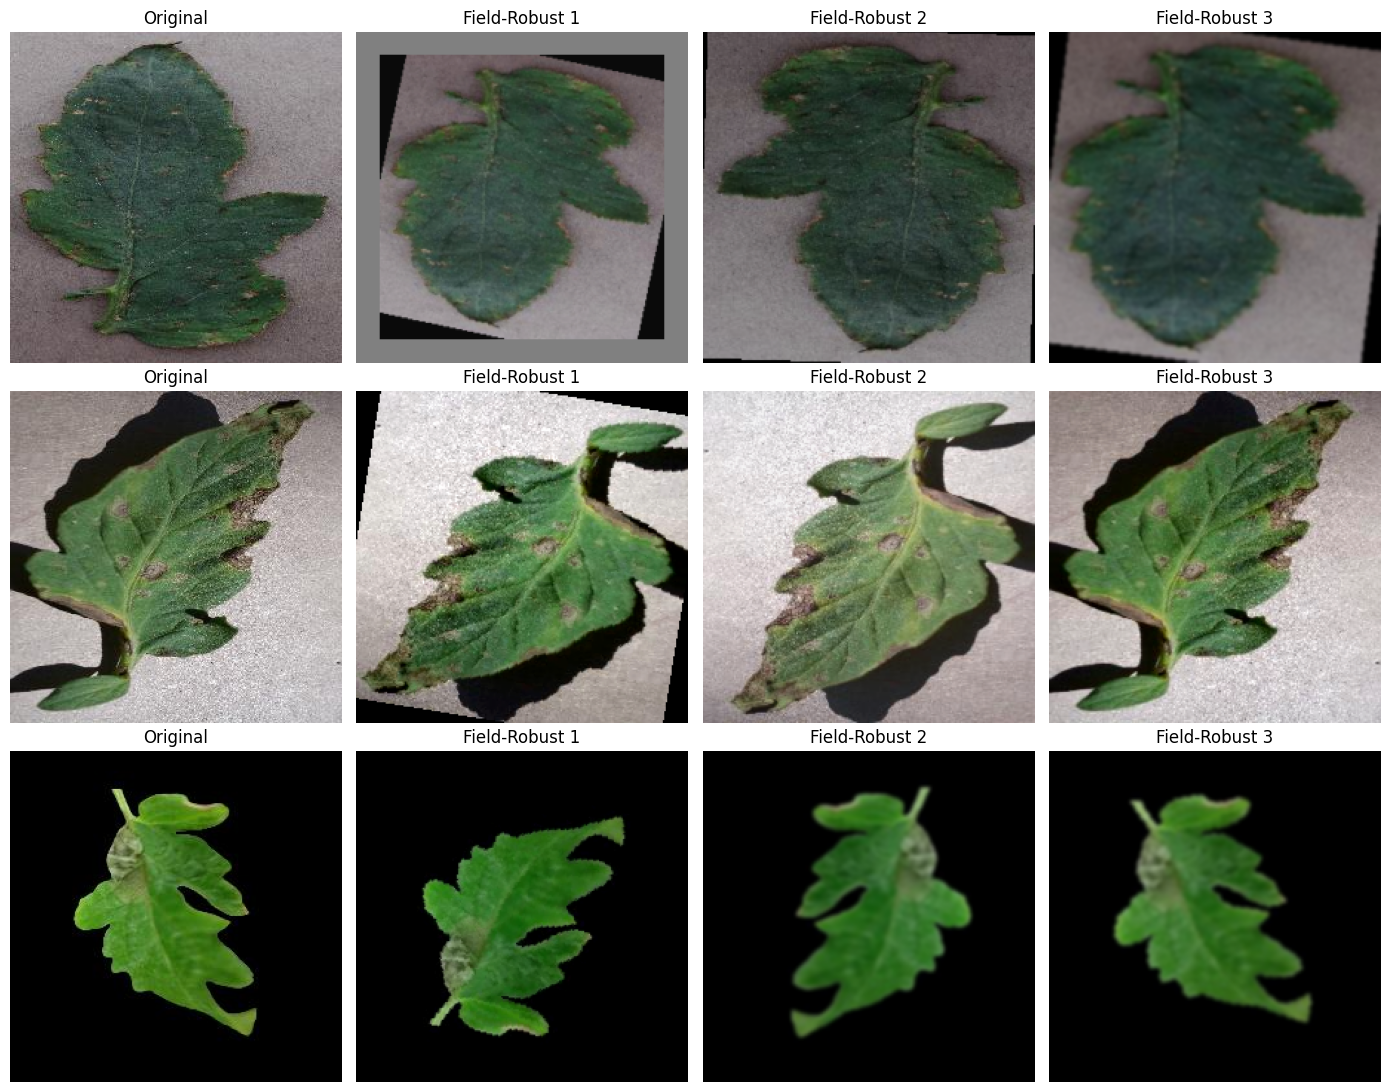

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

train_df = pd.read_csv(
    ROOT / "data/splits/pv_train.csv"
)

samples = (
    train_df.groupby("label_index")
    .sample(n=1, random_state=42)
    .head(3)
)

mean = np.array(
    data_cfg["mean"]
).reshape(3, 1, 1)

std = np.array(
    data_cfg["std"]
).reshape(3, 1, 1)


def restore_image(tensor):
    array = tensor.numpy()
    return np.clip(
        (array * std + mean).transpose(1, 2, 0),
        0, 1
    )


fig, axes = plt.subplots(
    3, 4, figsize=(14, 11)
)

for i, (_, row) in enumerate(samples.iterrows()):

    with Image.open(ROOT / row["image_path"]) as f:
        original = f.convert("RGB").copy()

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")

    for j in range(1, 4):
        augmented = E4_TRANSFORM(original)

        axes[i, j].imshow(
            restore_image(augmented)
        )

        axes[i, j].set_title(
            f"Field-Robust {j}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [1]:
from copy import deepcopy
from datetime import datetime, timezone
from uuid import uuid4

import pandas as pd
import src.train as train_module
from src.utils import load_config

# 复制 E4 配置，不影响原 E3 模型
formal_config = deepcopy(E4_CONFIG)

formal_config["experiment_stage"] = "E4"
formal_config["augmentation"] = "field_robust_v1"
formal_config["parent_run_id"] = E3_RUN.name
formal_config["smoke_test"] = False
formal_config.pop("smoke_limit", None)

# 正式训练参数
formal_config["training"]["epochs"] = 10
formal_config["training"]["batch_size"] = 16
formal_config["training"]["lr"] = 0.0001
formal_config["training"]["num_workers"] = 0

# 记录增强参数，便于复现
formal_config["augmentation_params"] = {
    "blur_probability": 0.35,
    "blur_sigma": [0.4, 1.4],
    "small_subject_probability": 0.20,
    "small_subject_scale": [0.70, 0.95],
    "lighting_probability": 0.15,
    "base_augmentation": "combined"
}

assert formal_config["model"]["name"] == "efficientnet_b0"
assert formal_config["model"]["finetuning"] == "full"
assert formal_config["seed"] == 42

run_id = (
    "e4_field_robust_v1_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
    + "_"
    + uuid4().hex[:6]
)

print("开始正式训练 E4")
print("实验名称：", run_id)

# 临时接入 E4 的数据增强
original_builder = train_module.build_transforms

try:
    train_module.build_transforms = build_e4_transforms

    E4_RUN = train_module.run_experiment(
        ROOT,
        formal_config,
        run_id=run_id
    )

finally:
    train_module.build_transforms = original_builder

# 查看训练结果
status = load_config(E4_RUN / "status.json")

print("\n训练状态：", status["status"])
print("训练轮数：", status["epochs_completed"])
print("最佳轮次：", status["best_epoch"])
print("最佳验证 Macro-F1：", status["best_score"])
print("训练耗时（秒）：", status["seconds"])
print("结果目录：", E4_RUN)

history = pd.read_csv(E4_RUN / "history.csv")
display(history)

ModuleNotFoundError: No module named 'src'